# Point Cloud Binary Classification with PyTorch

Make sure you are using the `cv-lab3` conda environment.

## Dataset Loading and Visualization

The input X contain 100 2D points, and y are their corresponding labels (0 or 1). The goal is to train a model that can classify every point to its correct label.


Matplotlib is building the font cache; this may take a moment.


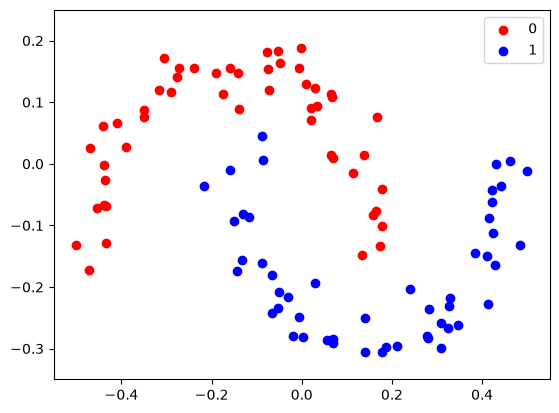

<Figure size 640x480 with 0 Axes>

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim import Adam

dataset = np.load('data/2d_pcl_dataset.npz')
X, y = dataset['X'], dataset['y']

X0 = X[y==0] # 50 2D points have label 0
X1 = X[y==1] # 50 2D points have label 1

def plot(X0, X1, fit_param=None):
    plt.scatter(X0[:,0], X0[:,1], color='red', label=0)
    plt.scatter(X1[:,0], X1[:,1], color='blue', label=1)
    
    plt.xlim([-0.55, 0.55])
    plt.ylim([-0.35, 0.25])
    plt.legend()
    plt.show()
    plt.clf()

plot(X0, X1)

## Logistic Regression for the Point Cloud Classification Task


Starting by filling in the `Simple2DDataset` class below. 

First, in the class constructor `__init__`, you will need to read the data `2d_pcl_dataset.npz` from disk (as above).

Second, in the function `__getitem__`, you need to return a single data point and its label based on its index `idx`.

In [3]:
class Simple2DDataset(Dataset):
    def __init__(self):
        super().__init__()
        #########################################################################
        # TODO: read data from disk using np.load.
        # Data is located in the folder "data".
        # Save samples and labels to class members self.X and self.y respectively.
        # samples should be an Nx2 numpy array. Labels should be a one-dimensional array of shape (N,).
        #########################################################################
        with np.load("data/2d_pcl_dataset.npz") as data:
            self.X = data["X"]
            self.y = data["y"].reshape(-1)
     
    def __len__(self):
        # Returns the number of samples in the dataset.
        return self.X.shape[0]
    
    def __getitem__(self, idx):
        #########################################################################
        # TODO: return the sample and label with index idx
        #########################################################################
        point = self.X[idx]
        label = self.y[idx]
        
        # Convert to tensor.
        return torch.from_numpy(point).float(), \
               torch.from_numpy(label[np.newaxis]).float()


With the complete `Simple2DDataset`, we can create a PyTorch dataloader

**NOTE**: if you encounter errors in data loading, try setting `NUM_WORKERS = 0` for a more informative error message

In [4]:
BATCH_SIZE = 8
NUM_WORKERS = 0

# create the dataloader
dataset = Simple2DDataset()
train_dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    num_workers=NUM_WORKERS,
    shuffle=True
)

Now, define your first network by filling in the `LinearClassifier` class below.

Add a single linear layer `nn.Linear` inside the `nn.Sequential` call. The input is 2D, and the output should be a single value, corresponding to the probability of a given 2D point being part of class 1. You can find a comprehensive overview and description of different torch.nn layers under the following link.

https://docs.pytorch.org/docs/stable/nn.html

In [5]:
class LinearClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.codename = 'linear'

        #########################################################################
        # TODO: add a single linear layer with nn.Linear, inside the `nn.Sequential` call.
        # Input is 2D.
        # Output is a single value.
        #########################################################################
        self.model = nn.Sequential(nn.Linear(2, 1))
        
    def forward(self, batch):
        # Process batch using the defined model.
        x = self.model(batch)
        # Final sigmoid activation to obtain a probability between 0 and 1.
        return torch.sigmoid(x)

Now, you are asked to implement the training loop below

In [6]:
def train(net, optimizer, dataloader, epoch):
    net.train()
    loss_sum = 0
    for batch_idx, (point, label) in enumerate(dataloader):
        # First we need to zero the gradient, otherwise PyTorch would accumulate them
        optimizer.zero_grad()

        #########################################################################
        #TODO: 
        # 1. forward pass of the network to obtain the predictions given the batch
        # 2. compute the loss using F.binary_cross_entropy
        # 3. backward pass on the loss using loss.backward(), and one step 
        # of gradient descent (optimization) using optimizer.step()
        #########################################################################
        output = net(point)
        loss = F.binary_cross_entropy(output, label)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()
    return loss_sum
        

You can now run the cell below to train the linear model.

In [7]:
NUM_EPOCHS = 100
# create the network.
net = LinearClassifier()

# create the optimizer.
optimizer = Adam(net.parameters(), lr=0.1)

best_accuracy = 0
for epoch_idx in range(NUM_EPOCHS):
    loss = train(net, optimizer, train_dataloader, epoch_idx)
    print('[Epoch %02d] Loss: %.4f' % (epoch_idx + 1, loss))

[Epoch 01] Loss: 8.2303
[Epoch 02] Loss: 6.7268
[Epoch 03] Loss: 5.8456
[Epoch 04] Loss: 5.3530
[Epoch 05] Loss: 5.1095
[Epoch 06] Loss: 4.6948
[Epoch 07] Loss: 4.6483
[Epoch 08] Loss: 4.3330
[Epoch 09] Loss: 4.2939
[Epoch 10] Loss: 4.3443
[Epoch 11] Loss: 4.1751
[Epoch 12] Loss: 4.1533
[Epoch 13] Loss: 3.8791
[Epoch 14] Loss: 3.8970
[Epoch 15] Loss: 3.8755
[Epoch 16] Loss: 3.8264
[Epoch 17] Loss: 3.7204
[Epoch 18] Loss: 3.6975
[Epoch 19] Loss: 3.7246
[Epoch 20] Loss: 3.6319
[Epoch 21] Loss: 3.6132
[Epoch 22] Loss: 3.6594
[Epoch 23] Loss: 3.5837
[Epoch 24] Loss: 3.5571
[Epoch 25] Loss: 3.5306
[Epoch 26] Loss: 3.6944
[Epoch 27] Loss: 3.7285
[Epoch 28] Loss: 3.5381
[Epoch 29] Loss: 3.7464
[Epoch 30] Loss: 3.4969
[Epoch 31] Loss: 3.8006
[Epoch 32] Loss: 3.5724
[Epoch 33] Loss: 3.5964
[Epoch 34] Loss: 3.5253
[Epoch 35] Loss: 3.5104
[Epoch 36] Loss: 3.4825
[Epoch 37] Loss: 3.5218
[Epoch 38] Loss: 3.4433
[Epoch 39] Loss: 3.5349
[Epoch 40] Loss: 3.7606
[Epoch 41] Loss: 3.5734
[Epoch 42] Loss:

[Epoch 75] Loss: 3.4952
[Epoch 76] Loss: 3.9563
[Epoch 77] Loss: 3.5285
[Epoch 78] Loss: 3.8874
[Epoch 79] Loss: 3.4729
[Epoch 80] Loss: 3.4470
[Epoch 81] Loss: 3.6327
[Epoch 82] Loss: 3.4661
[Epoch 83] Loss: 3.4567
[Epoch 84] Loss: 3.4385
[Epoch 85] Loss: 3.4335
[Epoch 86] Loss: 3.6687
[Epoch 87] Loss: 3.6808
[Epoch 88] Loss: 3.5457
[Epoch 89] Loss: 3.5624
[Epoch 90] Loss: 3.5448
[Epoch 91] Loss: 3.6467
[Epoch 92] Loss: 3.8021
[Epoch 93] Loss: 3.5009
[Epoch 94] Loss: 3.6651
[Epoch 95] Loss: 3.6777
[Epoch 96] Loss: 3.4543
[Epoch 97] Loss: 3.6033
[Epoch 98] Loss: 3.6968
[Epoch 99] Loss: 3.4397
[Epoch 100] Loss: 3.4714


Finally, plot your result below.


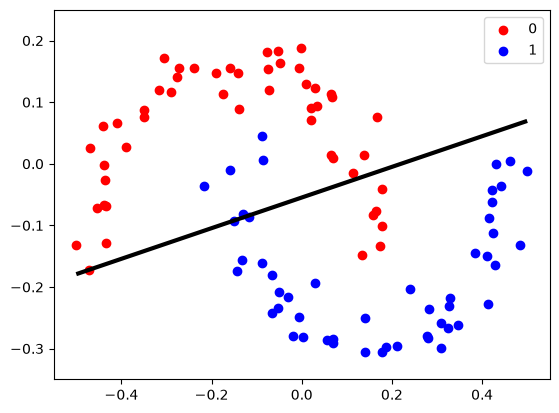

<Figure size 640x480 with 0 Axes>

In [8]:
p = np.linspace(-0.5, 0.5, 500)
x_plot, y_plot = np.meshgrid(p, p)
X_plot = np.stack((x_plot, y_plot), axis=2).reshape(-1, 2)
X_plot = torch.from_numpy(X_plot).float()
output = net(X_plot)
output = output.detach().numpy()
output = output.reshape(x_plot.shape[0], x_plot.shape[1])

plt.contour(x_plot, y_plot, output, [0.5],
                  colors=('k',),
                  linewidths=(3,))
plot(X0, X1)


### Implement your first Multi-Layer Perceptron (MLP) for Point Cloud Classification
You should notice that your logistic regression model cannot classify the point cloud correctly - as expected :) 
Therefore, we now implement an MLP for the same binary classification task.

In [9]:
# These are the parameters to be used
nInput = 2
nOutput = 1
nHidden = 16
act_fn = nn.ReLU()

class MLP(nn.Module):
    def __init__(self, nInput, nOutput, nHidden, act_fn):
        super().__init__()

        # Define the network layers in order.
        # Input is 2D (nInput).
        # Output is a single value (nOutput).
        # Multiple linear layers each followed by a ReLU non-linearity (apart from the last).
        #########################################################################
        # TODO: add a two-layer MLP, inside the `nn.Sequential` call.
        # Input is 2D.
        # Output is a single value.

        # Hint: unlike logistic regression where you need only one nn.Linear layer, 
        # here you will have two nn.Linear layers. After the first layer, we 
        # apply a ReLU activation function. The output is then passed to another 
        # linear layer. Note that you should use `nHidden` below as the hidden dimension 
        # of your linear layers.
        #########################################################################
        self.model = nn.Sequential(
            nn.Linear(nInput, nHidden),
            act_fn,
            nn.Linear(nHidden, nOutput)
        )
        
    def forward(self, batch):
        # Process batch using the defined model.
        x = self.model(batch)
        # Final sigmoid activation to obtain a probability.
        return torch.sigmoid(x)


Run the cell below to train the MLP.

In [10]:
NUM_EPOCHS = 200

# create the network.
net = MLP(nInput, nOutput, nHidden, act_fn)

# create the optimizer.
optimizer = Adam(net.parameters(), lr=0.1)

best_accuracy = 0
for epoch_idx in range(NUM_EPOCHS):
    loss = train(net, optimizer, train_dataloader, epoch_idx)
    print('[Epoch %02d] Loss: %.4f' % (epoch_idx + 1, loss))

[Epoch 01] Loss: 8.3757
[Epoch 02] Loss: 4.4497
[Epoch 03] Loss: 3.7077
[Epoch 04] Loss: 4.1173
[Epoch 05] Loss: 3.4892
[Epoch 06] Loss: 3.7626
[Epoch 07] Loss: 3.5843
[Epoch 08] Loss: 3.4214
[Epoch 09] Loss: 3.7305
[Epoch 10] Loss: 3.6957
[Epoch 11] Loss: 4.1809
[Epoch 12] Loss: 3.2618
[Epoch 13] Loss: 2.8057
[Epoch 14] Loss: 2.5853
[Epoch 15] Loss: 2.4830
[Epoch 16] Loss: 2.3353
[Epoch 17] Loss: 2.3358
[Epoch 18] Loss: 1.8078
[Epoch 19] Loss: 1.4126
[Epoch 20] Loss: 1.1705
[Epoch 21] Loss: 0.9957
[Epoch 22] Loss: 0.7775
[Epoch 23] Loss: 0.7171
[Epoch 24] Loss: 0.7097
[Epoch 25] Loss: 0.6989
[Epoch 26] Loss: 0.9799
[Epoch 27] Loss: 0.6591
[Epoch 28] Loss: 0.6419
[Epoch 29] Loss: 0.5888
[Epoch 30] Loss: 0.3749
[Epoch 31] Loss: 0.4411
[Epoch 32] Loss: 0.4567
[Epoch 33] Loss: 0.8912
[Epoch 34] Loss: 0.4216
[Epoch 35] Loss: 0.4248
[Epoch 36] Loss: 0.3895
[Epoch 37] Loss: 0.2819
[Epoch 38] Loss: 0.3127
[Epoch 39] Loss: 0.4435
[Epoch 40] Loss: 0.2886
[Epoch 41] Loss: 0.2103
[Epoch 42] Loss:

[Epoch 54] Loss: 0.0574
[Epoch 55] Loss: 0.0608
[Epoch 56] Loss: 0.0618
[Epoch 57] Loss: 0.0568
[Epoch 58] Loss: 0.0548
[Epoch 59] Loss: 0.0472
[Epoch 60] Loss: 0.0484
[Epoch 61] Loss: 0.0470
[Epoch 62] Loss: 0.0426
[Epoch 63] Loss: 0.0434
[Epoch 64] Loss: 0.0430
[Epoch 65] Loss: 0.0446
[Epoch 66] Loss: 0.0418
[Epoch 67] Loss: 0.0395
[Epoch 68] Loss: 0.0428
[Epoch 69] Loss: 0.0431
[Epoch 70] Loss: 0.0381
[Epoch 71] Loss: 0.0400
[Epoch 72] Loss: 0.0313
[Epoch 73] Loss: 0.0347
[Epoch 74] Loss: 0.0314
[Epoch 75] Loss: 0.0271
[Epoch 76] Loss: 0.0288
[Epoch 77] Loss: 0.0268
[Epoch 78] Loss: 0.0267
[Epoch 79] Loss: 0.0254
[Epoch 80] Loss: 0.0255
[Epoch 81] Loss: 0.0261
[Epoch 82] Loss: 0.0280
[Epoch 83] Loss: 0.0246
[Epoch 84] Loss: 0.0223
[Epoch 85] Loss: 0.0240
[Epoch 86] Loss: 0.0199
[Epoch 87] Loss: 0.0251
[Epoch 88] Loss: 0.0216
[Epoch 89] Loss: 0.0202
[Epoch 90] Loss: 0.0219
[Epoch 91] Loss: 0.0222
[Epoch 92] Loss: 0.0215
[Epoch 93] Loss: 0.0239
[Epoch 94] Loss: 0.0195
[Epoch 95] Loss:

[Epoch 107] Loss: 0.0138
[Epoch 108] Loss: 0.0130
[Epoch 109] Loss: 0.0133
[Epoch 110] Loss: 0.0133
[Epoch 111] Loss: 0.0126
[Epoch 112] Loss: 0.0124
[Epoch 113] Loss: 0.0119
[Epoch 114] Loss: 0.0131
[Epoch 115] Loss: 0.0109
[Epoch 116] Loss: 0.0113
[Epoch 117] Loss: 0.0105
[Epoch 118] Loss: 0.0105
[Epoch 119] Loss: 0.0107
[Epoch 120] Loss: 0.0101
[Epoch 121] Loss: 0.0098
[Epoch 122] Loss: 0.0093
[Epoch 123] Loss: 0.0119
[Epoch 124] Loss: 0.0097
[Epoch 125] Loss: 0.0100
[Epoch 126] Loss: 0.0094
[Epoch 127] Loss: 0.0093
[Epoch 128] Loss: 0.0094
[Epoch 129] Loss: 0.0090
[Epoch 130] Loss: 0.0084
[Epoch 131] Loss: 0.0110
[Epoch 132] Loss: 0.0103
[Epoch 133] Loss: 0.0082
[Epoch 134] Loss: 0.0083
[Epoch 135] Loss: 0.0094
[Epoch 136] Loss: 0.0089
[Epoch 137] Loss: 0.0080
[Epoch 138] Loss: 0.0084
[Epoch 139] Loss: 0.0084
[Epoch 140] Loss: 0.0072
[Epoch 141] Loss: 0.0072
[Epoch 142] Loss: 0.0069
[Epoch 143] Loss: 0.0070
[Epoch 144] Loss: 0.0084
[Epoch 145] Loss: 0.0078
[Epoch 146] Loss: 0.0072


[Epoch 161] Loss: 0.0050
[Epoch 162] Loss: 0.0051
[Epoch 163] Loss: 0.0054
[Epoch 164] Loss: 0.0052
[Epoch 165] Loss: 0.0050
[Epoch 166] Loss: 0.0047
[Epoch 167] Loss: 0.0050
[Epoch 168] Loss: 0.0048
[Epoch 169] Loss: 0.0055
[Epoch 170] Loss: 0.0045
[Epoch 171] Loss: 0.0052
[Epoch 172] Loss: 0.0044
[Epoch 173] Loss: 0.0047
[Epoch 174] Loss: 0.0048
[Epoch 175] Loss: 0.0042
[Epoch 176] Loss: 0.0043
[Epoch 177] Loss: 0.0053
[Epoch 178] Loss: 0.0043
[Epoch 179] Loss: 0.0045
[Epoch 180] Loss: 0.0040
[Epoch 181] Loss: 0.0041
[Epoch 182] Loss: 0.0038
[Epoch 183] Loss: 0.0040
[Epoch 184] Loss: 0.0044
[Epoch 185] Loss: 0.0038
[Epoch 186] Loss: 0.0038
[Epoch 187] Loss: 0.0043
[Epoch 188] Loss: 0.0038
[Epoch 189] Loss: 0.0036
[Epoch 190] Loss: 0.0044
[Epoch 191] Loss: 0.0035
[Epoch 192] Loss: 0.0036
[Epoch 193] Loss: 0.0035
[Epoch 194] Loss: 0.0033
[Epoch 195] Loss: 0.0032
[Epoch 196] Loss: 0.0032
[Epoch 197] Loss: 0.0031
[Epoch 198] Loss: 0.0031
[Epoch 199] Loss: 0.0032
[Epoch 200] Loss: 0.0035


Finally, plot your results again. You should see that the decision boundary can now clearly separate the point clouds.


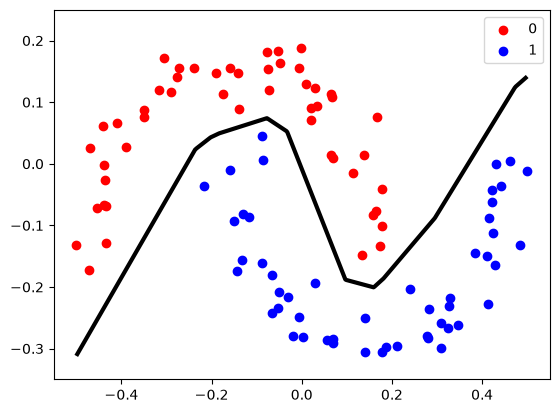

<Figure size 640x480 with 0 Axes>

In [11]:
p = np.linspace(-0.5, 0.5, 500)
x_plot, y_plot = np.meshgrid(p, p)
X_plot = np.stack((x_plot, y_plot), axis=2).reshape(-1, 2)
X_plot = torch.from_numpy(X_plot).float()
output = net(X_plot)
output = output.detach().numpy()
output = output.reshape(x_plot.shape[0], x_plot.shape[1])

plt.contour(x_plot, y_plot, output, [0.5],
                  colors=('k',),
                  linewidths=(3,))
plot(X0, X1)

When you are done, move forward to `image_classification.ipynb`.